**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: Alejandro Rendón De Jesús
*   MATRÍCULA: A01664589

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [2]:
cardio_df = pd.read_csv('heart_disease.csv', index_col='id')
cardio_df.head()

,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
id,,,,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [3]:
cardio_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


chol        216
thalch      119
trestbps     60
oldpeak      53
age          50
num           5
origin        4
cp            4
ca            4
restecg       3
slope         3
thal          3
sex           2
fbs           2
exang         2
dtype: int64


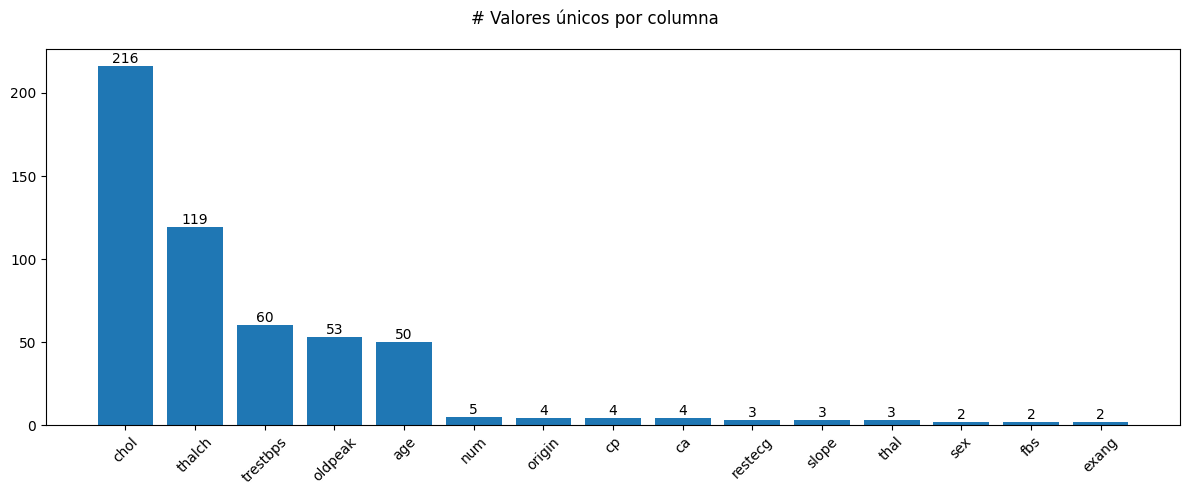

In [4]:
unique_values = cardio_df.nunique().sort_values(ascending=False)
print(unique_values)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(unique_values.index, unique_values.values)
ax.bar_label(bars)
ax.tick_params(axis='x', rotation=45)
plt.suptitle('# Valores únicos por columna')
plt.tight_layout()
plt.show()

**Respuesta 1.** El dataframe tiene 918 registros y 15 columnas (sin contar `id`, que quedó como índice).

* **Numéricas: 7** → 2 `int64` (`age`, `num`) y 5 `float64` (`trestbps`, `chol`, `thalch`, `oldpeak`, `ca`).
* **De texto (`object`): 8** → `sex`, `origin`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `thal`. (`fbs` y `exang` en realidad son booleanas, pero pandas las lee como `object` porque tienen valores faltantes.)

Valores únicos por columna: `chol` 216, `thalch` 119, `trestbps` 60, `oldpeak` 53, `age` 50, `num` 5, `origin` 4, `cp` 4, `ca` 4, `restecg` 3, `slope` 3, `thal` 3, `sex` 2, `fbs` 2, `exang` 2.

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [5]:
num_cols = cardio_df.select_dtypes(include='number').columns
print(unique_values[num_cols].sort_values())

ca            4
num           5
age          50
oldpeak      53
trestbps     60
thalch      119
chol        216
dtype: int64


**Respuesta 2.** Las variables numéricas con muy pocos valores únicos son `ca` (4) y `num` (5); el resto tiene 50 o más, por lo que sí son continuas/discretas reales.

* `ca`: número de vasos principales coloreados (0, 1, 2, 3). Es **ordinal**, ya que más vasos implica mayor afectación: 0 < 1 < 2 < 3.
* `num`: diagnóstico / grado de enfermedad (0 = sano, 1–4 = grados de enfermedad). Es **ordinal**: 0 < 1 < 2 < 3 < 4.

Ambas se convierten a categóricas **ordenadas** (`CategoricalDtype(..., ordered=True)`).

In [6]:
from pandas.api.types import CategoricalDtype

# ca: número de vasos coloreados (0 < 1 < 2 < 3) -> ordinal
cardio_df['ca'] = cardio_df['ca'].astype(CategoricalDtype(categories=[0.0, 1.0, 2.0, 3.0], ordered=True))

# num: grado de enfermedad (0 = sano < 1 < 2 < 3 < 4) -> ordinal
cardio_df['num'] = cardio_df['num'].astype(CategoricalDtype(categories=[0, 1, 2, 3, 4], ordered=True))

print(cardio_df['ca'].dtype, cardio_df['ca'].cat.categories.tolist())
print(cardio_df['num'].dtype, cardio_df['num'].cat.categories.tolist())

category [0.0, 1.0, 2.0, 3.0]
category [0, 1, 2, 3, 4]


3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [7]:
num_cols = cardio_df.select_dtypes(include='number').columns.tolist()
cat_cols = cardio_df.columns.difference(num_cols, sort=False).tolist()
print('Numéricas:', num_cols)
print('Categóricas:', cat_cols)

desc_num = cardio_df[num_cols].describe().T
desc_num['skew'] = cardio_df[num_cols].skew()
desc_num['kurtosis'] = cardio_df[num_cols].kurt()
desc_num

Numéricas: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
Categóricas: ['sex', 'origin', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'num']


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
age,918.0,53.530501,9.412783,28.0,47.0,54.0,60.0,77.0,-0.193710,-0.382511
trestbps,859.0,132.294529,18.535875,80.0,120.0,130.0,140.0,200.0,0.630411,0.632992
chol,888.0,242.189189,53.424806,85.0,216.0,223.0,268.0,603.0,1.640672,6.573848
thalch,863.0,137.528389,25.950226,60.0,120.0,140.0,157.0,202.0,-0.209319,-0.483939
oldpeak,856.0,0.880607,1.091840,-2.6,0.0,0.5,1.5,6.2,1.037990,1.119834


In [8]:
cardio_df[cat_cols].astype('object').describe().T

,count,unique,top,freq
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
fbs,829,2,False,691
restecg,918,3,normal,551
exang,863,2,False,526
slope,610,3,flat,345
ca,309.0,4.0,0.0,181.0
thal,434,3,normal,196
num,918,5,0,411


In [9]:
for col in cat_cols:
    freq = pd.concat([cardio_df[col].value_counts(dropna=False),
                      cardio_df[col].value_counts(dropna=False, normalize=True).mul(100).round(2)],
                     axis=1, keys=['frecuencia', '%'])
    print(f'--- {col} ---')
    print(freq, end='\n\n')

--- sex ---
        frecuencia      %
sex                      
Male           724  78.87
Female         194  21.13

--- origin ---
               frecuencia      %
origin                          
Cleveland             304  33.12
Hungary               292  31.81
VA Long Beach         200  21.79
Switzerland           122  13.29

--- cp ---
                 frecuencia      %
cp                                
asymptomatic            495  53.92
non-anginal             204  22.22
atypical angina         174  18.95
typical angina           45   4.90

--- fbs ---
       frecuencia      %
fbs                     
False         691  75.27
True          138  15.03
NaN            89   9.69

--- restecg ---
                  frecuencia      %
restecg                            
normal                   551  60.02
lv hypertrophy           188  20.48
st-t abnormality         179  19.50

--- exang ---
       frecuencia      %
exang                   
False         526  57.30
True          337  36.7

**Interpretación 3.**

* `age` y `thalch` son casi simétricas (sesgo ≈ −0.2) y con curtosis ligeramente negativa (platicúrticas).
* `trestbps` tiene un sesgo positivo moderado (0.63).
* `chol` es la más asimétrica (sesgo 1.64) y leptocúrtica (curtosis 6.57): tiene colas largas con valores extremos (máximo 603 mg/dl).
* `oldpeak` también tiene sesgo positivo (1.04): la mayoría de los pacientes tiene valores cercanos a 0.
* En las categóricas predominan los hombres (78.9 %), el dolor torácico asintomático (53.9 %) y el ECG normal (60 %). La variable objetivo `num` está desbalanceada: 44.8 % sanos y solo 3 % en el grado 4. Además, `ca`, `thal` y `slope` tienen una gran proporción de faltantes.

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [10]:
missing_pct = cardio_df.isna().mean().mul(100).round(2).sort_values(ascending=False)
missing_pct

ca          66.34
thal        52.72
slope       33.55
fbs          9.69
oldpeak      6.75
trestbps     6.43
thalch       5.99
exang        5.99
chol         3.27
age          0.00
sex          0.00
origin       0.00
cp           0.00
restecg      0.00
num          0.00
dtype: float64

In [11]:
cols_to_drop = missing_pct[missing_pct > 30].index.tolist()
print('Columnas eliminadas:', cols_to_drop)
cardio_df = cardio_df.drop(columns=cols_to_drop)

Columnas eliminadas: ['ca', 'thal', 'slope']


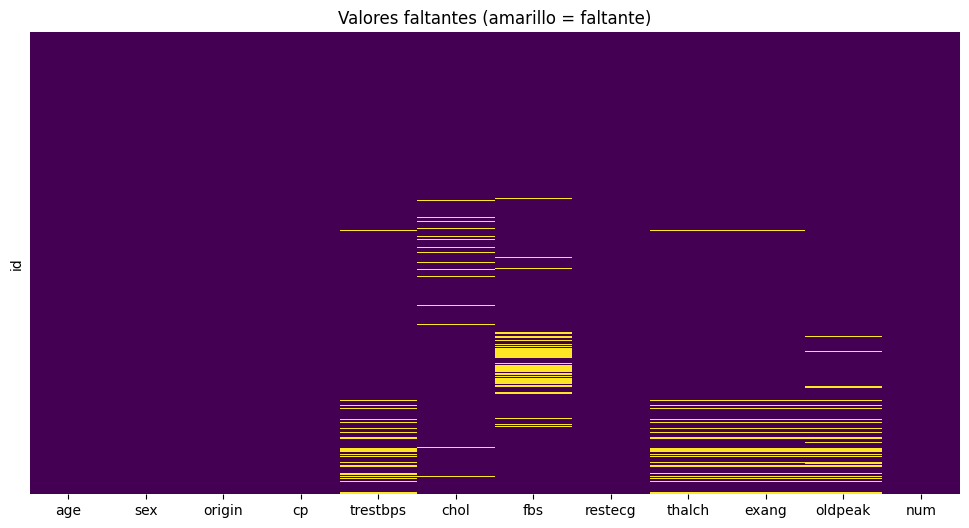

In [12]:
plt.figure(figsize=(12, 6))
sns.heatmap(cardio_df.isna(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Valores faltantes (amarillo = faltante)')
plt.show()

In [13]:
# Patrones de faltantes conjuntos y su relación con el origen del estudio
mv = cardio_df.isna()
print(mv[mv.any(axis=1)].value_counts(), end='\n\n')
print(pd.crosstab(cardio_df['thalch'].isna(), cardio_df['origin'], rownames=['thalch faltante']))

age    sex    origin  cp     trestbps  chol   fbs    restecg  thalch  exang  oldpeak  num  
False  False  False   False  False     False  True   False    False   False  False    False    85
                             True      False  False  False    True    True   True     False    51
                             False     True   False  False    False   False  False    False    27
                                       False  False  False    False   False  True     False     4
                                              True   False    False   False  True     False     3
                             True      False  False  False    False   False  False    False     3
                                       True   False  False    True    True   True     False     3
                                       False  False  False    True    True   False    False     1
                                              True   False    False   False  True     False     1
Name: count, dtype: int64


**Respuesta 4.**

* Se eliminaron **`ca` (66.3 %)**, **`thal` (52.7 %)** y **`slope` (33.6 %)** porque superan el 30 % de faltantes.
* En el mapa de calor y en la tabla de patrones se ve que **`thalch`, `exang` y `oldpeak`** suelen faltar juntas, y en la mayoría de esos casos también **`trestbps`** (51 registros tienen las cuatro ausentes al mismo tiempo).

**¿Tiene sentido clínico?** Sí. `thalch` (frecuencia cardíaca máxima), `exang` (angina inducida por ejercicio) y `oldpeak` (depresión del ST con ejercicio) se obtienen de la **misma prueba de esfuerzo** (ergometría). Si al paciente no se le hizo la prueba, ya sea por contraindicación clínica, por su estado de salud o porque el centro no la registró, faltan las tres a la vez. `trestbps` se mide en el mismo contexto de evaluación de ingreso, y casi todos estos faltantes vienen del centro **VA Long Beach** (53 de 55 faltantes de `thalch` y 56 de 59 de `trestbps`), lo que apunta a una forma distinta de recolectar los datos en ese hospital. Por otro lado, `fbs` y `chol` faltan por separado (son análisis de laboratorio, otro procedimiento), sobre todo en Suiza (`fbs`) y Hungría (`chol`).

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [14]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [15]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

In [16]:
BM_MV = cardio_df['thalch'].isna()
print(BM_MV.value_counts())

thalch
False    863
True      55
Name: count, dtype: int64


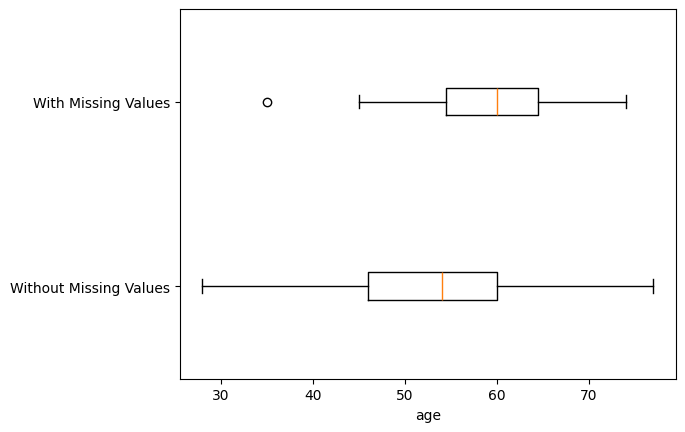

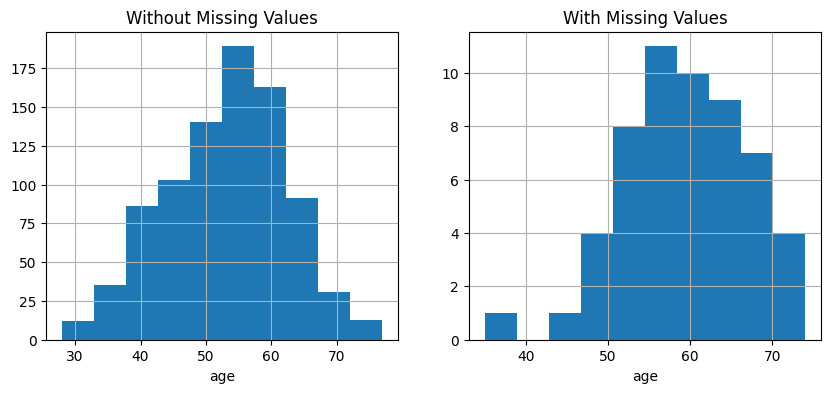

p-value of t-test: 1.5041244185890902e-06


In [17]:
Diagnose_MV_Numerical(cardio_df, 'age', BM_MV)

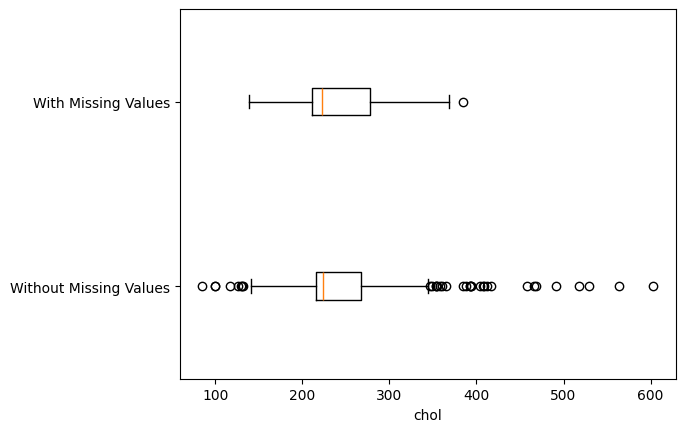

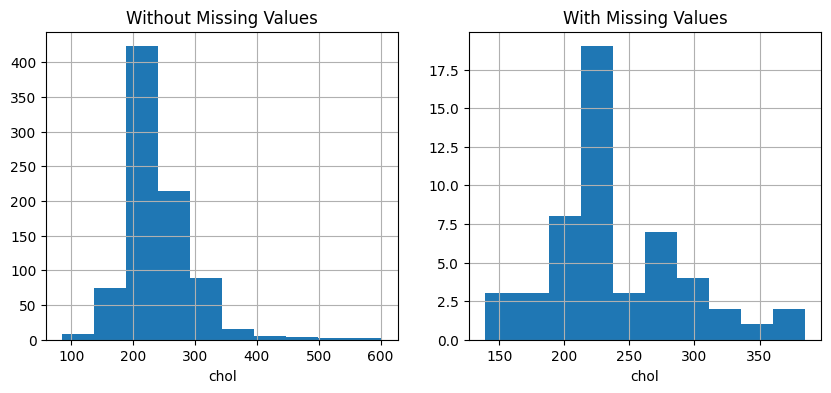

p-value of t-test: 0.7165289974295672


In [18]:
Diagnose_MV_Numerical(cardio_df, 'chol', BM_MV)

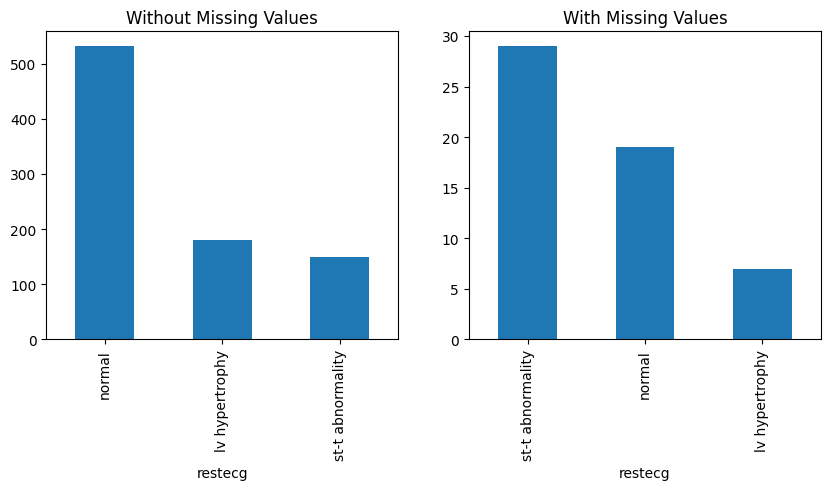

p-value of Chi_squared test: 1.1472889573985465e-09


In [19]:
Diagnose_MV_Categorical(cardio_df, 'restecg', BM_MV)

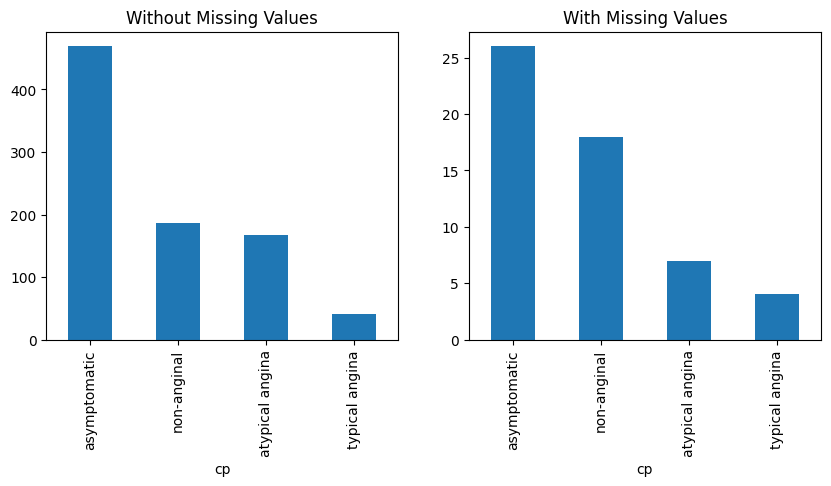

p-value of Chi_squared test: 0.15420097177251701


In [20]:
Diagnose_MV_Categorical(cardio_df, 'cp', BM_MV)

**Conclusiones 5.** Se compararon los registros con y sin faltantes en `thalch` (α = 0.05):

| Variable | Prueba | p-value | ¿Diferencia significativa? |
|---|---|---|---|
| `age` | t de Student | 1.5 × 10⁻⁶ | **Sí**: los pacientes sin `thalch` son mayores (media 59.4 vs 53.2 años) |
| `chol` | t de Student | 0.717 | No (medias 239.6 vs 242.4) |
| `restecg` | χ² | 1.1 × 10⁻⁹ | **Sí**: 52.7 % de los faltantes tienen anomalía ST-T vs 17.4 % de los no faltantes |
| `cp` | χ² | 0.154 | No |

La ausencia de `thalch` **no es independiente** de las demás variables: depende de la edad y del resultado del electrocardiograma en reposo (y, como se vio en el ejercicio 4, del centro de origen, `origin`). Clínicamente tiene sentido: a pacientes mayores o con alteraciones del ST-T en reposo se les puede evitar o suspender la prueba de esfuerzo.

Por lo tanto, el mecanismo **no es MCAR**, ya que en ese caso no habría diferencias sistemáticas entre ambos grupos. Se trata de **MAR**, porque la probabilidad de que falte `thalch` puede explicarse con variables observadas (`age`, `restecg`, `origin`). Esto justifica imputar por grupos usando `restecg` en el ejercicio 6. Por lo mismo, este hallazgo se puede extender a `exang`, `oldpeak` y `trestbps`, que comparten el patrón.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

In [21]:
group_num = ['thalch', 'trestbps', 'oldpeak']
group_cat = ['exang']

print(cardio_df.groupby('restecg')[group_num].median())

for col in group_num:
    cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(x.median()))

# exang es categórica (True/False): se imputa con la moda de cada grupo
for col in group_cat:
    cardio_df[col] = cardio_df[col].astype('boolean')
    cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(x.mode()[0])).astype(bool)

cardio_df[group_num + group_cat].isna().sum()

                  thalch  trestbps  oldpeak
restecg                                    
lv hypertrophy     146.0     130.0      0.8
normal             140.0     130.0      0.2
st-t abnormality   129.0     130.0      0.9


thalch      0
trestbps    0
oldpeak     0
exang       0
dtype: int64

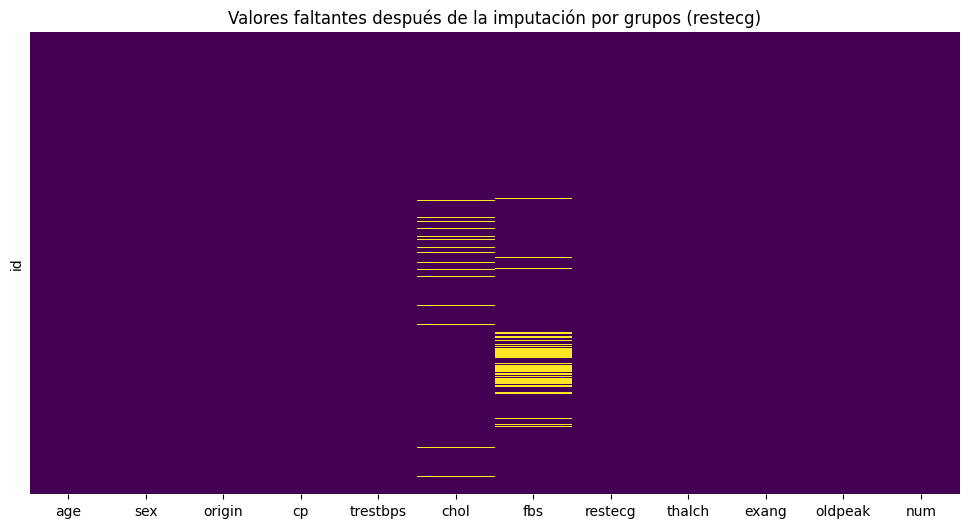

In [22]:
plt.figure(figsize=(12, 6))
sns.heatmap(cardio_df.isna(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Valores faltantes después de la imputación por grupos (restecg)')
plt.show()

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [23]:
print(cardio_df.isna().sum()[cardio_df.isna().sum() > 0])
print('Sesgo de chol:', round(cardio_df['chol'].skew(), 3))

chol    30
fbs     89
dtype: int64
Sesgo de chol: 1.641


In [24]:
# chol: numérica con sesgo y valores atípicos -> mediana
imp_median = SimpleImputer(strategy='median')
cardio_df[['chol']] = imp_median.fit_transform(cardio_df[['chol']])

# fbs: categórica binaria (True/False) -> moda
imp_mode = SimpleImputer(strategy='most_frequent')
cardio_df[['fbs']] = imp_mode.fit_transform(cardio_df[['fbs']].astype('object'))
cardio_df['fbs'] = cardio_df['fbs'].astype(bool)

print('Mediana usada en chol:', imp_median.statistics_)
print('Moda usada en fbs:', imp_mode.statistics_)
print('Faltantes restantes:', cardio_df.isna().sum().sum())

Mediana usada en chol: [223.]
Moda usada en fbs: [False]
Faltantes restantes: 0


**Justificación 7.** Después de la imputación por grupos, solo `chol` (30) y `fbs` (89) tenían faltantes.

* **`chol` → `median`**: es numérica, pero tiene un fuerte sesgo positivo (1.64) y muchos atípicos (hasta 603 mg/dl). La media se ve arrastrada por esos extremos, mientras que la mediana (223) es robusta y representa mejor al paciente típico.
* **`fbs` → `most_frequent`**: es categórica binaria (True/False), así que no se puede calcular media ni mediana. Se usa la moda (`False`, 75 % de los casos).

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

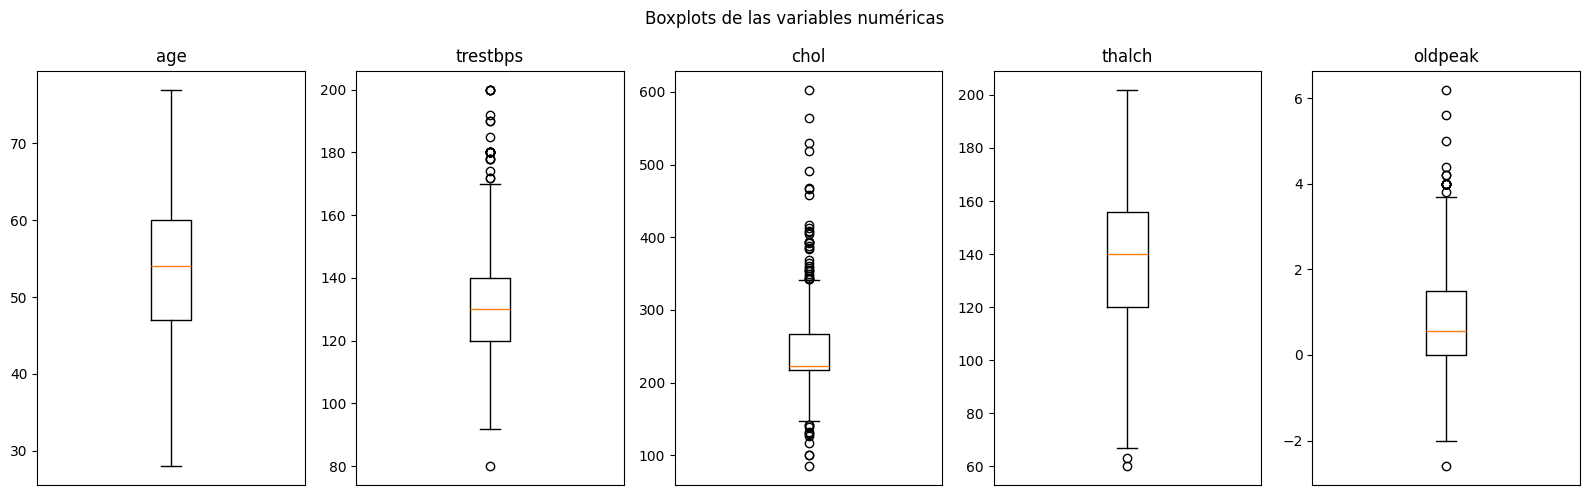

age: 0 atípicos -> []
trestbps: 27 atípicos -> [ 80. 172. 172. 174. 178. 178. 178. 180. 180. 180. 180. 180. 180. 180.
 180. 180. 180. 180. 180. 185. 190. 190. 192. 200. 200. 200. 200.]
chol: 44 atípicos -> [ 85. 100. 100. 117. 126. 129. 131. 132. 139. 141. 142. 342. 342. 342.
 344. 347. 349. 353. 354. 355. 358. 360. 365. 369. 384. 385. 388. 392.
 393. 394. 394. 404. 407. 409. 412. 417. 458. 466. 468. 491. 518. 529.
 564. 603.]
thalch: 2 atípicos -> [60. 63.]
oldpeak: 16 atípicos -> [-2.6  3.8  4.   4.   4.   4.   4.   4.   4.   4.   4.2  4.2  4.4  5.
  5.6  6.2]


In [25]:
num_cols = cardio_df.select_dtypes(include='number').columns.tolist()

fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 5))
outliers = {}
for ax, col in zip(axes, num_cols):
    bp = ax.boxplot(cardio_df[col])
    ax.set_title(col)
    ax.set_xticks([])
    outliers[col] = np.sort(bp['fliers'][0].get_ydata())
plt.suptitle('Boxplots de las variables numéricas')
plt.tight_layout()
plt.show()

for col, vals in outliers.items():
    print(f'{col}: {len(vals)} atípicos -> {vals}')

**Respuesta 8.** Valores atípicos obtenidos de `bp['fliers']` (puntos fuera de los bigotes, Q1 − 1.5·IQR y Q3 + 1.5·IQR):

* `age`: 0 atípicos.
* `trestbps`: 27 atípicos (80 por abajo; de 172 a 200 por arriba).
* `chol`: 44 atípicos (de 85 a 142 por abajo; de 342 a 603 por arriba).
* `thalch`: 2 atípicos (60 y 63).
* `oldpeak`: 16 atípicos (−2.6 y de 3.8 a 6.2).

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [26]:
q1 = cardio_df['trestbps'].quantile(0.25)
q3 = cardio_df['trestbps'].quantile(0.75)
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr
print(f'Q1 = {q1}, Q3 = {q3}, IQR = {iqr}')
print(f'Límite inferior = {lim_inf}, límite superior = {lim_sup}')

mask_out = (cardio_df['trestbps'] < lim_inf) | (cardio_df['trestbps'] > lim_sup)
iqr_outliers = np.sort(cardio_df.loc[mask_out, 'trestbps'].values)
print(f'{len(iqr_outliers)} atípicos por IQR -> {iqr_outliers}')
print('¿Coinciden con el boxplot?', np.array_equal(iqr_outliers, outliers['trestbps']))

Q1 = 120.0, Q3 = 140.0, IQR = 20.0
Límite inferior = 90.0, límite superior = 170.0
27 atípicos por IQR -> [ 80. 172. 172. 174. 178. 178. 178. 180. 180. 180. 180. 180. 180. 180.
 180. 180. 180. 180. 180. 185. 190. 190. 192. 200. 200. 200. 200.]
¿Coinciden con el boxplot? True


**Respuesta 9.** Q1 = 120, Q3 = 140, IQR = 20, por lo que el límite inferior es 120 − 1.5·20 = **90** y el superior es 140 + 1.5·20 = **170**. Hay **27 valores** fuera de ese rango (80 y de 172 a 200), y **coinciden exactamente** con los fliers del boxplot del ejercicio 8. Es lo esperado, porque `matplotlib` usa el mismo criterio de 1.5·IQR para dibujar los bigotes.

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

Registros antes: 918
Registros después: 891


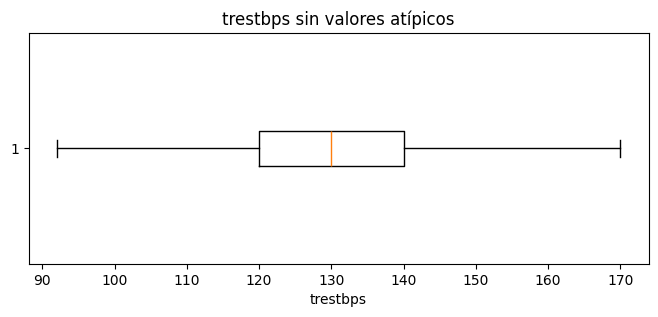

In [27]:
print('Registros antes:', len(cardio_df))
cardio_df = cardio_df[~mask_out]
print('Registros después:', len(cardio_df))

plt.figure(figsize=(8, 3))
plt.boxplot(cardio_df['trestbps'], vert=False)
plt.xlabel('trestbps')
plt.title('trestbps sin valores atípicos')
plt.show()

**Respuesta 10.** Se eliminaron los 27 registros con `trestbps` atípico (918 → 891 filas). En el boxplot final, la distribución queda entre 90 y 170 mm Hg (Q1 = 120, Q3 = 140) y ya **no aparecen nuevos valores atípicos**: al recalcular los cuartiles con los datos depurados no cambian, así que los bigotes siguen en 90 y 170.

---

# Anexo: matemática y uso de las técnicas empleadas

Esta sección explica el fundamento matemático de cada técnica del notebook, cuándo conviene usarla y cuáles son sus limitaciones. Cada fórmula se verifica calculándola "a mano" con `numpy` y comparándola con el resultado de `pandas`, `scipy` o `sklearn`.

Para que el anexo no dependa de las transformaciones anteriores, se trabaja sobre una copia limpia del archivo original (`raw`).

In [28]:
from scipy import stats

raw = pd.read_csv('heart_disease.csv', index_col='id')
x = raw['chol'].dropna().to_numpy()
n = len(x)
print('n =', n)

n = 888


## A.1 Tipos de variables y codificación categórica

| Escala | Ejemplo | Operaciones válidas | Estadístico de tendencia central |
|---|---|---|---|
| Nominal | `sex`, `cp`, `origin` | $=, \neq$ | moda |
| Ordinal | `ca`, `num` | $=, \neq, <, >$ | moda, mediana |
| Intervalo / razón | `age`, `chol`, `thalch` | $+, -, \times, \div$ | moda, mediana, media |

Una variable almacenada como número no es necesariamente cuantitativa. Si tiene pocos valores únicos, representa categorías y el número es solo una etiqueta. En el caso de `num`, la "distancia" entre 0 y 1 no tiene por qué ser igual a la que hay entre 3 y 4.

**Uso en pandas:** `CategoricalDtype(categories=[...], ordered=True)` guarda el orden. Así funcionan comparaciones como `s > 1`, `min`/`max` y la ordenación, y las bibliotecas y los modelos no tratan la variable como continua. Internamente se guarda un código entero por categoría (`.cat.codes`), lo que también ahorra memoria.

In [29]:
num_ord = raw['num'].astype(CategoricalDtype([0, 1, 2, 3, 4], ordered=True))
print(num_ord.cat.codes.head().tolist())
print('Pacientes con grado > 2:', (num_ord > 2).sum())

[0, 2, 1, 0, 0]
Pacientes con grado > 2: 135


## A.2 Estadística descriptiva: media, desviación estándar, sesgo y curtosis

Para una muestra $x_1, \dots, x_n$:

$$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i \qquad s = \sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2}$$

El denominador $n-1$ (corrección de Bessel) hace que $s^2$ sea un estimador **insesgado** de la varianza poblacional.

**Sesgo (asimetría).** Con los momentos centrales $m_k = \frac{1}{n}\sum (x_i-\bar{x})^k$, el coeficiente de Fisher–Pearson es $g_1 = m_3 / m_2^{3/2}$. `pandas.skew()` aplica la corrección por muestra finita:

$$G_1 = \frac{\sqrt{n(n-1)}}{n-2}\, g_1$$

* $G_1 > 0$: cola larga a la derecha (media > mediana), como en `chol` y `oldpeak`.
* $G_1 < 0$: cola larga a la izquierda.
* $|G_1| < 0.5$: distribución aproximadamente simétrica.

**Curtosis (exceso).** $g_2 = m_4/m_2^2 - 3$ (la normal tiene curtosis 3, es decir, exceso 0). `pandas.kurt()` usa el estimador insesgado:

$$G_2 = \frac{n-1}{(n-2)(n-3)}\left[(n+1)\,g_2 + 6\right]$$

* $G_2 > 0$ (leptocúrtica): colas pesadas, con más valores extremos que una normal. Es el caso de `chol` ($G_2 \approx 6.6$).
* $G_2 < 0$ (platicúrtica): colas ligeras.

**Uso:** el sesgo y la curtosis indican si la media es representativa, si conviene imputar con la mediana y si una variable necesitará una transformación (log, Box-Cox) antes de usar modelos que suponen normalidad.

In [30]:
m2 = np.mean((x - x.mean())**2)
m3 = np.mean((x - x.mean())**3)
m4 = np.mean((x - x.mean())**4)

g1 = m3 / m2**1.5
G1 = np.sqrt(n*(n-1)) / (n-2) * g1
g2 = m4 / m2**2 - 3
G2 = (n-1) / ((n-2)*(n-3)) * ((n+1)*g2 + 6)

print(f'Sesgo    a mano = {G1:.6f} | pandas = {raw["chol"].skew():.6f}')
print(f'Curtosis a mano = {G2:.6f} | pandas = {raw["chol"].kurt():.6f}')

Sesgo    a mano = 1.640672 | pandas = 1.640672
Curtosis a mano = 6.573848 | pandas = 6.573848


## A.3 Valores faltantes: mecanismos MCAR, MAR y MNAR

Sea $X$ la matriz de datos, con una parte observada $X_{obs}$ y otra faltante $X_{mis}$, y sea $M$ la matriz indicadora ($M_{ij}=1$ si $x_{ij}$ falta). La clasificación de Rubin (1976) depende de qué condiciona la probabilidad de faltar:

| Mecanismo | Definición | Ejemplo en este dataset |
|---|---|---|
| **MCAR** | $P(M \mid X_{obs}, X_{mis}) = P(M)$ | Se perdió una hoja al azar |
| **MAR** | $P(M \mid X_{obs}, X_{mis}) = P(M \mid X_{obs})$ | `thalch` falta más en pacientes mayores, con alteración ST-T o de VA Long Beach (todas observadas) |
| **MNAR** | $P(M)$ depende de $X_{mis}$ | No se registra el colesterol justo porque es muy alto |

**Consecuencias prácticas:**
* MCAR: eliminar filas (*listwise deletion*) no introduce sesgo, solo hace perder potencia estadística.
* MAR: eliminar filas sí sesga los resultados. La imputación debe condicionarse en las variables que explican la ausencia, como en la imputación por grupos del ejercicio 6.
* MNAR: no se puede detectar solo con los datos observados. Requiere conocimiento del dominio o modelos de selección.

**Diagnóstico (lo que hacen `Diagnose_MV_*`):** se define el indicador $B = \mathbb{1}[\text{thalch es NaN}]$ y se prueba si otras variables se distribuyen igual en $B=1$ y $B=0$. Si alguna difiere significativamente, se rechaza MCAR. Lo que no se puede descartar con estas pruebas es MNAR.

**Regla del 30 %:** cuando falta una fracción tan grande de una columna (`ca`, `thal`, `slope`), cualquier imputación "inventa" una parte importante de la información y distorsiona la varianza y las correlaciones. Por eso es preferible eliminar esas columnas.

## A.4 Prueba t de Student para dos muestras independientes

Sirve para comparar la media de una variable **numérica** entre dos grupos (con y sin faltantes en `thalch`).

* $H_0: \mu_1 = \mu_2$ frente a $H_1: \mu_1 \neq \mu_2$.
* `ttest_ind` usa por defecto varianzas iguales (`equal_var=True`), con la varianza combinada:

$$s_p^2 = \frac{(n_1-1)s_1^2 + (n_2-1)s_2^2}{n_1+n_2-2} \qquad t = \frac{\bar{x}_1-\bar{x}_2}{s_p\sqrt{\frac{1}{n_1}+\frac{1}{n_2}}}$$

* Bajo $H_0$, $t \sim t_{n_1+n_2-2}$. El p-value bilateral es $p = 2\,P(T > |t|)$.
* Si $p < \alpha = 0.05$, se rechaza $H_0$: las medias difieren.

**Supuestos:** independencia, normalidad aproximada en cada grupo (por el TCL basta con $n$ grande) y varianzas similares. Con grupos de tamaño muy distinto (55 frente a 863) es más robusta la versión de **Welch** (`equal_var=False`), que no supone varianzas iguales. Si la variable es muy asimétrica, la alternativa no paramétrica es **Mann-Whitney U**. Abajo se comprueba que la conclusión sobre `age` no cambia con estas alternativas.

In [31]:
B = raw['thalch'].isna()
g1_, g2_ = raw.loc[B, 'age'].to_numpy(), raw.loc[~B, 'age'].to_numpy()
n1, n2 = len(g1_), len(g2_)

sp2 = ((n1-1)*g1_.var(ddof=1) + (n2-1)*g2_.var(ddof=1)) / (n1+n2-2)
t = (g1_.mean() - g2_.mean()) / np.sqrt(sp2 * (1/n1 + 1/n2))
p = 2 * stats.t.sf(abs(t), df=n1+n2-2)

print(f't a mano = {t:.4f}, p = {p:.3e}')
print('scipy (Student):', stats.ttest_ind(g1_, g2_))
print('scipy (Welch):  ', stats.ttest_ind(g1_, g2_, equal_var=False))
print('Mann-Whitney U: ', stats.mannwhitneyu(g1_, g2_))

t a mano = 4.8426, p = 1.504e-06


scipy (Student): TtestResult(statistic=4.842568379953884, pvalue=1.5041244185890902e-06, df=916.0)
scipy (Welch):   TtestResult(statistic=5.640020193812004, pvalue=4.115876441882053e-07, df=64.14292542014078)
Mann-Whitney U:  MannwhitneyuResult(statistic=32840.5, pvalue=1.7571343908603145e-06)


## A.5 Prueba $\chi^2$ de independencia

Sirve para variables **categóricas**: ¿la distribución de `restecg` es la misma con y sin faltantes en `thalch`?

* $H_0$: el indicador de faltante y la variable categórica son independientes.
* Se construye la tabla de contingencia de $r \times c$ con frecuencias observadas $O_{ij}$. Bajo independencia, las frecuencias esperadas son:

$$E_{ij} = \frac{(\text{total fila } i)(\text{total columna } j)}{N} \qquad \chi^2 = \sum_{i,j}\frac{(O_{ij}-E_{ij})^2}{E_{ij}}$$

* Bajo $H_0$, $\chi^2 \sim \chi^2_{(r-1)(c-1)}$.
* **Supuesto:** $E_{ij} \geq 5$ en (casi) todas las celdas. Si no se cumple, se usa la prueba exacta de Fisher o se agrupan categorías. `chi2_contingency` aplica la corrección de Yates solo en tablas de 2×2.
* El p-value indica si hay asociación, pero no qué tan fuerte es. Para medir la magnitud se usa la **V de Cramér**: $V = \sqrt{\chi^2 / (N\,(\min(r,c)-1))}$, que va de 0 (independencia) a 1.

In [32]:
O = pd.crosstab(B, raw['restecg']).to_numpy()
N = O.sum()
E = O.sum(axis=1, keepdims=True) * O.sum(axis=0, keepdims=True) / N
chi2 = ((O - E)**2 / E).sum()
dof = (O.shape[0]-1) * (O.shape[1]-1)
p = stats.chi2.sf(chi2, dof)
V = np.sqrt(chi2 / (N * (min(O.shape) - 1)))

print('Frecuencias esperadas:\n', E.round(1))
print(f'chi2 a mano = {chi2:.4f}, gl = {dof}, p = {p:.3e}, V de Cramér = {V:.3f}')
print('scipy:', stats.chi2_contingency(O)[:3])

Frecuencias esperadas:
 [[176.7 518.  168.3]
 [ 11.3  33.   10.7]]
chi2 a mano = 41.1717, gl = 2, p = 1.147e-09, V de Cramér = 0.212
scipy: (41.1717282120588, 1.1472889573985465e-09, 2)


## A.6 Imputación: media, mediana, moda y por grupos

Cada estadístico de imputación es el valor constante que **minimiza una función de pérdida**:

| Estrategia | Minimiza | Propiedad | Cuándo usarla |
|---|---|---|---|
| `mean` | $\sum (x_i - c)^2$ | Sensible a atípicos | Numérica y aproximadamente simétrica |
| `median` | $\sum \lvert x_i - c\rvert$ | Robusta (punto de ruptura del 50 %) | Numérica asimétrica o con atípicos (`chol`) |
| `most_frequent` | $\sum \mathbb{1}[x_i \neq c]$ | Única válida para nominales | Categórica o booleana (`fbs`, `exang`) |

**Efecto secundario:** imputar con una constante reduce artificialmente la varianza y concentra los valores en un pico. Si se imputa el $k\%$ de los datos con la media, la varianza queda multiplicada aproximadamente por $(1-k)$.

**Imputación por grupos (condicional):** en lugar de $\hat{x} = \text{mediana}(X)$ se usa $\hat{x}_i = \text{mediana}(X \mid G = g_i)$. Bajo MAR, si $G$ explica parte de la ausencia, esto reduce el sesgo: a un paciente con anomalía ST-T se le imputa la `thalch` típica de ese grupo (129) y no la global (140). Con `groupby(...).transform(...)` se obtiene una serie alineada con el índice original, lista para reasignarse a la columna.

**`SimpleImputer` frente a `fillna`:** el imputer de sklearn **aprende** el estadístico con `fit` (y lo guarda en `statistics_`) y lo aplica con `transform`. En un flujo de ML se ajusta solo con el conjunto de entrenamiento y se aplica igual al de prueba (dentro de un `Pipeline`), lo que evita *data leakage*.

In [33]:
from scipy.optimize import minimize_scalar

c_mean = minimize_scalar(lambda c: np.sum((x - c)**2)).x
c_med = minimize_scalar(lambda c: np.sum(np.abs(x - c)), bounds=(x.min(), x.max()), method='bounded').x
print(f'argmin pérdida cuadrática = {c_mean:.2f} | media   = {x.mean():.2f}')
print(f'argmin pérdida absoluta   = {c_med:.2f} | mediana = {np.median(x):.2f}')

k = raw['chol'].isna().mean()
imp = raw['chol'].fillna(raw['chol'].mean())
print(f'\nVarianza original = {raw["chol"].var(ddof=0):.1f}; tras imputar con la media = {imp.var(ddof=0):.1f}; '
      f'predicción (1-k)·var = {(1-k)*raw["chol"].var(ddof=0):.1f}')

argmin pérdida cuadrática = 242.19 | media   = 242.19
argmin pérdida absoluta   = 223.00 | mediana = 223.00

Varianza original = 2851.0; tras imputar con la media = 2757.8; predicción (1-k)·var = 2757.8


## A.7 Valores atípicos: cuartiles, IQR y boxplot (vallas de Tukey)

**Cuantiles.** `pandas.quantile` y `np.percentile` usan por defecto interpolación lineal. Con los datos ordenados $x_{(1)} \le \dots \le x_{(n)}$, el cuantil $q$ está en la posición $h = (n-1)q$ (indexada desde 0):

$$Q(q) = x_{(\lfloor h \rfloor)} + (h - \lfloor h \rfloor)\,\big(x_{(\lfloor h \rfloor + 1)} - x_{(\lfloor h \rfloor)}\big)$$

**Vallas de Tukey.** Con $\text{IQR} = Q_3 - Q_1$:

$$L_{inf} = Q_1 - 1.5\,\text{IQR} \qquad L_{sup} = Q_3 + 1.5\,\text{IQR}$$

`plt.boxplot` usa por defecto `whis=1.5`: los bigotes llegan al dato más extremo **dentro** de las vallas y lo que queda fuera se dibuja como *flier*. Por eso el método gráfico (ejercicio 8) y el analítico (ejercicio 9) coinciden exactamente.

**¿Por qué 1.5?** Si $X \sim N(\mu, \sigma)$: $Q_3 \approx \mu + 0.674\sigma$ y $\text{IQR} \approx 1.349\sigma$, de modo que $L_{sup} \approx \mu + 2.698\sigma$. La probabilidad de quedar fuera de las vallas es de apenas $\approx 0.7\%$. Con $k=3$ se obtienen las vallas "extremas" ($\approx \mu \pm 4.7\sigma$).

**Uso y precauciones:**
* El IQR es robusto: a diferencia de la regla $\bar{x} \pm 3s$, no se infla con los propios atípicos.
* En distribuciones asimétricas (`chol`, `oldpeak`), la regla marca muchos puntos en la cola larga que son valores **legítimos**. Antes de eliminarlos hay que valorar si son errores de medición o casos clínicos reales: una presión de 200 mm Hg es posible en un paciente hipertenso.
* Eliminar filas reduce la muestra. La **winsorización** (recortar los valores a $L_{inf}$ y $L_{sup}$) o una transformación son alternativas que no pierden registros.

In [34]:
t_ = np.sort(raw['trestbps'].dropna().to_numpy())

def cuantil_lineal(xs, q):
    h = (len(xs) - 1) * q
    lo = int(np.floor(h))
    return xs[lo] + (h - lo) * (xs[min(lo + 1, len(xs) - 1)] - xs[lo])

Q1, Q3 = cuantil_lineal(t_, 0.25), cuantil_lineal(t_, 0.75)
print(f'Q1 a mano = {Q1}, Q3 a mano = {Q3} | numpy = {np.percentile(t_, [25, 75])}')

p_out = 2 * stats.norm.sf(stats.norm.ppf(0.75) + 1.5 * (stats.norm.ppf(0.75) - stats.norm.ppf(0.25)))
print(f'P(fuera de las vallas | normal) = {p_out:.4%}')

L_inf, L_sup = Q1 - 1.5*(Q3-Q1), Q3 + 1.5*(Q3-Q1)
wins = raw['trestbps'].clip(L_inf, L_sup)
print(f'Winsorización: min = {wins.min()}, max = {wins.max()}, se conservan los {wins.notna().sum()} registros')

Q1 a mano = 120.0, Q3 a mano = 140.0 | numpy = [120. 140.]
P(fuera de las vallas | normal) = 0.6977%
Winsorización: min = 90.0, max = 170.0, se conservan los 859 registros


## A.8 Resumen del flujo de preprocesamiento

1. **Tipificar** correctamente (numérica, nominal u ordinal), porque de eso depende qué estadísticos y pruebas son válidos.
2. **Describir** cada variable (tendencia, dispersión, forma) para elegir la imputación y detectar problemas.
3. **Diagnosticar faltantes**: medir el porcentaje, ver los patrones conjuntos e identificar el mecanismo con pruebas t y $\chi^2$.
4. **Imputar** de acuerdo con el mecanismo: por grupos si es MAR y con un estadístico robusto según la forma de la distribución.
5. **Tratar atípicos** con criterio estadístico (IQR) y clínico, eliminando o winsorizando según el caso.

---

**Declaración de uso de IA**

*   Google. (2026). *Gemini* [Modelo de lenguaje grande], utilizado para generación de código. https://gemini.google.com/

---